Starting SUMO simulation...
SUMO started successfully.
Step:   500/10000 | Phase: 2 | Action: 0 | Current Queue:   2 | Avg Queue: 2.08 | Avg Reward: -2.08 | States: 31
Step:  1000/10000 | Phase: 0 | Action: 0 | Current Queue:   3 | Avg Queue: 2.75 | Avg Reward: -2.75 | States: 34
Step:  1500/10000 | Phase: 2 | Action: 1 | Current Queue:   3 | Avg Queue: 2.75 | Avg Reward: -2.75 | States: 34
Step:  2000/10000 | Phase: 0 | Action: 1 | Current Queue:   2 | Avg Queue: 2.82 | Avg Reward: -2.82 | States: 34
Step:  2500/10000 | Phase: 2 | Action: 1 | Current Queue:   3 | Avg Queue: 2.71 | Avg Reward: -2.71 | States: 34
Step:  3000/10000 | Phase: 0 | Action: 1 | Current Queue:   3 | Avg Queue: 2.89 | Avg Reward: -2.89 | States: 34
Step:  3500/10000 | Phase: 2 | Action: 0 | Current Queue:   2 | Avg Queue: 2.72 | Avg Reward: -2.72 | States: 34
Step:  4000/10000 | Phase: 0 | Action: 1 | Current Queue:   3 | Avg Queue: 2.78 | Avg Reward: -2.78 | States: 36
Step:  4500/10000 | Phase: 2 | Action: 0 

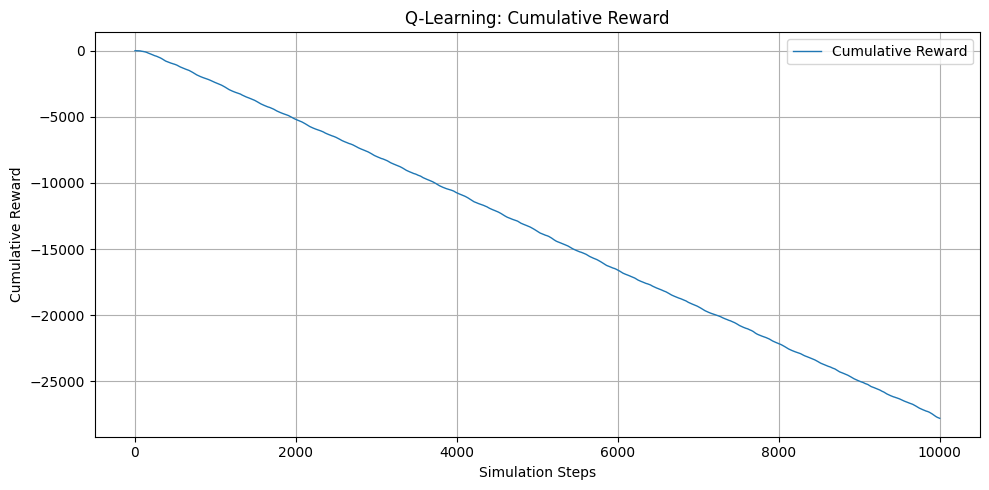

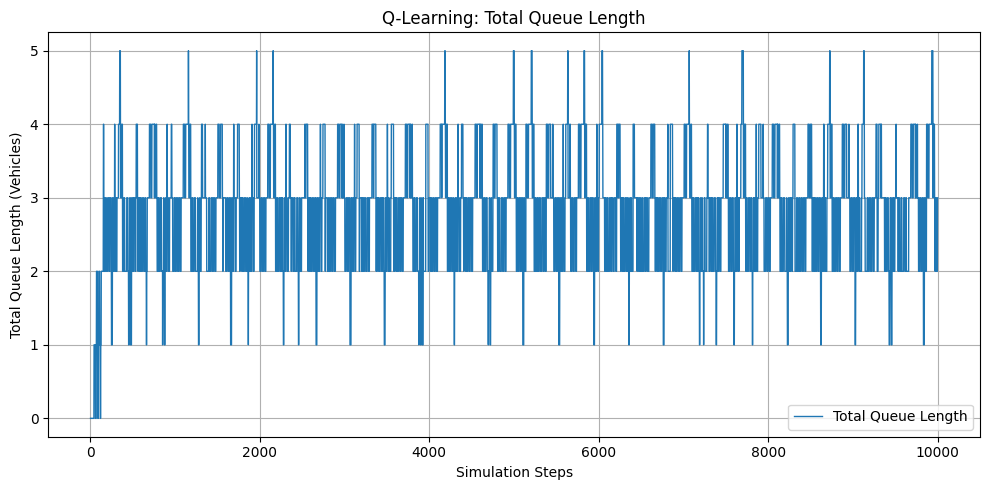


TRAINING COMPLETED SUCCESSFULLY
CSV file: Q_learning_results.csv
Plots saved:
- Q_learning_cumulative_reward.png
- Q_learning_queue_length.png


In [1]:
# Q-LEARNING TRAFFIC SIGNAL CONTROL WITH SUMO & TRACI

# ------------------------------------------------------------
# STEP 1: IMPORT LIBRARIES
# ------------------------------------------------------------

import os
import sys
import random
import csv
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# STEP 2: SET UP SUMO ENVIRONMENT
# ------------------------------------------------------------

if "SUMO_HOME" in os.environ:

    tools = os.path.join(os.environ["SUMO_HOME"], "tools")

    if tools not in sys.path:
        sys.path.append(tools)

else:
    sys.exit("Error: SUMO_HOME environment variable is not defined.")

import traci


# ------------------------------------------------------------
# STEP 3: SUMO CONFIGURATION
# ------------------------------------------------------------

# Run without GUI for faster training
SUMO_BINARY = "sumo"

SUMO_CONFIG = "RL.sumocfg"

sumo_cmd = [
    SUMO_BINARY,
    "-c", SUMO_CONFIG,
    "--step-length", "0.10",
    "--lateral-resolution", "0",
    "--no-step-log", "true",
    "--duration-log.disable"
]


# ------------------------------------------------------------
# STEP 4: DEFINE DETECTORS
# ------------------------------------------------------------

# Eastbound
EB_DETECTORS = [
    "Node1-2-EB-0",
    "Node1-2-EB-1",
    "Node1-2-EB-2"
]

# Southbound
SB_DETECTORS = [
    "Node1-2-SB-0",
    "Node1-2-SB-1",
    "Node1-2-SB-2"
]

# Combine all detectors
DETECTORS = EB_DETECTORS + SB_DETECTORS


# ------------------------------------------------------------
# STEP 5: TRAFFIC LIGHT ID
# ------------------------------------------------------------

TLS_ID = "Node2"


# ------------------------------------------------------------
# STEP 6: Q-LEARNING PARAMETERS
# ------------------------------------------------------------

TOTAL_STEPS = 10000

ALPHA = 0.1
GAMMA = 0.9
EPSILON = 0.1

# Action 0 = Keep current phase
# Action 1 = Switch to next phase

ACTIONS = [0, 1]

# Minimum green time
MIN_GREEN_STEPS = 100

# 100 steps x 0.10 seconds = 10 seconds
last_switch_step = -MIN_GREEN_STEPS


# ------------------------------------------------------------
# STEP 7: INITIALIZE Q-TABLE
# ------------------------------------------------------------

Q_TABLE = {}


def get_q_values(state):

    if state not in Q_TABLE:

        Q_TABLE[state] = {
            action: 0.0
            for action in ACTIONS
        }

    return Q_TABLE[state]


# ------------------------------------------------------------
# STEP 8: GET CURRENT STATE
# ------------------------------------------------------------

def get_state():

    queue_lengths = [
        traci.lanearea.getLastStepVehicleNumber(detector_id)
        for detector_id in DETECTORS
    ]

    current_phase = traci.trafficlight.getPhase(TLS_ID)

    state = tuple(queue_lengths) + (current_phase,)

    return state


# ------------------------------------------------------------
# STEP 9: REWARD FUNCTION
# ------------------------------------------------------------

def get_reward(state):

    # State contains 6 detector queues + traffic light phase
    total_queue = sum(state[:-1])

    # Negative queue length
    reward = -total_queue

    return reward


# ------------------------------------------------------------
# STEP 10: ACTION SELECTION
# ------------------------------------------------------------

def choose_action(state):

    q_values = get_q_values(state)

    # Exploration
    if random.random() < EPSILON:

        action = random.choice(ACTIONS)

    # Exploitation
    else:

        action = max(q_values, key=q_values.get)

    return action


# ------------------------------------------------------------
# STEP 11: APPLY ACTION
# ------------------------------------------------------------

def apply_action(action, current_step):

    global last_switch_step

    # Action 0: Keep current phase
    if action == 0:
        return

    # Action 1: Switch phase
    if action == 1:

        # Check minimum green time
        if current_step - last_switch_step >= MIN_GREEN_STEPS:

            program_logics = traci.trafficlight.getAllProgramLogics(TLS_ID)

            num_phases = len(program_logics[0].phases)

            current_phase = traci.trafficlight.getPhase(TLS_ID)

            next_phase = (current_phase + 1) % num_phases

            traci.trafficlight.setPhase(TLS_ID, next_phase)

            last_switch_step = current_step


# ------------------------------------------------------------
# STEP 12: UPDATE Q-TABLE
# ------------------------------------------------------------

def update_q_table(state, action, reward, next_state):

    q_values = get_q_values(state)

    next_q_values = get_q_values(next_state)

    old_q = q_values[action]

    best_future_q = max(next_q_values.values())

    new_q = old_q + ALPHA * (
        reward + GAMMA * best_future_q - old_q
    )

    Q_TABLE[state][action] = new_q


# ------------------------------------------------------------
# STEP 13: INITIALIZE PERFORMANCE METRICS
# ------------------------------------------------------------

cumulative_reward = 0

cumulative_rewards = []
queue_history = []
reward_history = []

phase_history = []
action_history = []

# Progress reporting interval
PRINT_INTERVAL = 500


# ------------------------------------------------------------
# STEP 14: START SUMO
# ------------------------------------------------------------

print("Starting SUMO simulation...")

traci.start(sumo_cmd)

print("SUMO started successfully.")

# Reset minimum green counter
last_switch_step = -MIN_GREEN_STEPS


# ------------------------------------------------------------
# STEP 15: RUN Q-LEARNING
# ------------------------------------------------------------

try:

    for step in range(TOTAL_STEPS):

        # Get current state
        state = get_state()

        # Select action
        action = choose_action(state)

        # Apply action
        apply_action(action, step)

        # Advance SUMO simulation
        traci.simulationStep()

        # Get next state
        next_state = get_state()

        # Calculate reward
        reward = get_reward(next_state)

        # Update cumulative reward
        cumulative_reward += reward

        # Update Q-table
        update_q_table(
            state,
            action,
            reward,
            next_state
        )

        # Record queue length
        total_queue = sum(next_state[:-1])

        # Store metrics
        cumulative_rewards.append(cumulative_reward)

        queue_history.append(total_queue)

        reward_history.append(reward)

        phase_history.append(next_state[-1])

        action_history.append(action)

        # Print progress periodically
        if (step + 1) % PRINT_INTERVAL == 0:

            average_queue = np.mean(
                queue_history[-PRINT_INTERVAL:]
            )

            average_reward = np.mean(
                reward_history[-PRINT_INTERVAL:]
            )

            print(
                f"Step: {step + 1:5d}/{TOTAL_STEPS} | "
                f"Phase: {next_state[-1]} | "
                f"Action: {action} | "
                f"Current Queue: {total_queue:3d} | "
                f"Avg Queue: {average_queue:.2f} | "
                f"Avg Reward: {average_reward:.2f} | "
                f"States: {len(Q_TABLE)}"
            )


finally:

    # Always close SUMO
    if traci.isLoaded():

        traci.close()

    print("\nSUMO simulation finished.")


# ------------------------------------------------------------
# STEP 16: DISPLAY FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("Q-LEARNING SIMULATION RESULTS")
print("=" * 50)

print("Total simulation steps:", len(cumulative_rewards))
print("Total states explored:", len(Q_TABLE))
print("Final cumulative reward:", cumulative_reward)

if queue_history:

    print(
        "Average queue length:",
        round(np.mean(queue_history), 2)
    )

    print(
        "Maximum queue length:",
        max(queue_history)
    )

    print(
        "Minimum queue length:",
        min(queue_history)
    )

    print(
        "Final queue length:",
        queue_history[-1]
    )


# ------------------------------------------------------------
# STEP 17: SAVE RESULTS TO CSV
# ------------------------------------------------------------

output_file = "Q_learning_results.csv"

with open(output_file, "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Step",
        "Action",
        "Phase",
        "Queue_Length",
        "Reward",
        "Cumulative_Reward"
    ])

    for i in range(len(queue_history)):

        writer.writerow([
            i + 1,
            action_history[i],
            phase_history[i],
            queue_history[i],
            reward_history[i],
            cumulative_rewards[i]
        ])

print(f"\nResults saved to: {output_file}")


# ------------------------------------------------------------
# STEP 18: PLOT CUMULATIVE REWARD
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_rewards) + 1),
    cumulative_rewards,
    linewidth=1,
    label="Cumulative Reward"
)

plt.xlabel("Simulation Steps")
plt.ylabel("Cumulative Reward")
plt.title("Q-Learning: Cumulative Reward")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "Q_learning_cumulative_reward.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# STEP 19: PLOT TOTAL QUEUE LENGTH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(queue_history) + 1),
    queue_history,
    linewidth=1,
    label="Total Queue Length"
)

plt.xlabel("Simulation Steps")
plt.ylabel("Total Queue Length (Vehicles)")
plt.title("Q-Learning: Total Queue Length")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "Q_learning_queue_length.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# STEP 20: FINAL MESSAGE
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("TRAINING COMPLETED SUCCESSFULLY")
print("=" * 50)

print("CSV file:", output_file)

print("Plots saved:")
print("- Q_learning_cumulative_reward.png")
print("- Q_learning_queue_length.png")